# 5. Производные признаки и декомпозиция

Всё, что мы использовали до сих пор, — готовые трансформы ETNA и колонки, которые уже
лежат в данных. Но библиотека не покрывает всё, и рано или поздно признак нужно
**посчитать самому**.

Три способа получить то, чего нет в ETNA:

1. **Арифметика над готовыми признаками** — `BinaryOperationTransform`. Отношение,
   разность, произведение двух колонок.
2. **Взаимодействия** — тот же `BinaryOperationTransform` с оператором `*`.
3. **Свой трансформ** — класс на `IrreversibleTransform`, если ни арифметика, ни готовые
   трансформы не выражают идею.

Идея, которую мы будем проверять: **ряд раскладывается на тренд, сезонность и остаток**,
и каждый компонент может быть отдельным признаком. Это не всегда помогает — но научиться
это делать нужно: половина «магии» в соревнованиях по временным рядам — именно в таких
ручных признаках.

In [1]:
import common  # первым: глушит предупреждения ETNA при импорте

common.quiet()

import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
from etna.models import LinearPerSegmentModel  # noqa: E402
from etna.transforms import (  # noqa: E402
    BinaryOperationTransform,
    FilterFeaturesTransform,
    FourierTransform,
    HolidayTransform,
    LagTransform,
    LinearTrendTransform,
    MeanTransform,
    STLTransform,
)
from etna.transforms.base import IrreversibleTransform  # noqa: E402

HORIZON = 14
raw = pd.read_csv(common.ROOT.parent / "data" / "onion_sales.csv", parse_dates=["day"])
raw = raw.rename(columns={"day": "timestamp", "rto": "target"}).assign(segment="onion")
onion = common.make_ts(raw)

# база — то, с чем мы закончили ноутбук 4
CALENDAR = [
    LinearTrendTransform(in_column="target"),
    *common.dow(),
    FourierTransform(period=365.25, order=3, out_column="f365"),
]
LAGS = [LagTransform(in_column="target", lags=[14, 21, 28, 35, 364], out_column="lag")]
BASE = CALENDAR + [HolidayTransform(iso_code="RUS", out_column="holiday")] + LAGS

## 1. Арифметика над признаками: `BinaryOperationTransform`

`BinaryOperationTransform(left_column, right_column, operator, out_column)` берёт две
**существующие** колонки и кладёт результат третьей. Операторы: `+`, `-`, `*`, `/`.

Зачем это нужно. Лаг `lag_14` — это абсолютный уровень две недели назад. Если магазин
растёт, лаг тоже растёт, и модель путает «выросли продажи» с «прошло время». Отношение
двух лагов — **безразмерное**: модель перестаёт зависеть от масштаба магазина и видит
только форму изменения.

Посмотрим на колонки на **сырых** уровнях ряда — без вычитания тренда и без других
трансформов. Так видно, что именно лежит в новых колонках.

In [2]:
mean28 = MeanTransform(in_column="lag_14", window=28, out_column="mean28")
ratio = BinaryOperationTransform(
    left_column="lag_14", right_column="mean28", operator="/", out_column="ratio_14_28"
)
diff = BinaryOperationTransform(
    left_column="lag_14", right_column="mean28", operator="-", out_column="diff_14_28"
)

demo = common.load_onion()  # отдельная копия: fit_transform меняет ts на месте
for transform in LAGS + [mean28, ratio, diff]:
    transform.fit_transform(demo)

frame = demo.to_pandas()["onion"]
window = frame.loc["2020-12-20":, ["lag_14", "mean28", "ratio_14_28", "diff_14_28"]]
print(window.round(3).to_string())
print("\nNaN в начале ряда:", frame[["lag_14", "mean28", "ratio_14_28", "diff_14_28"]].isna().sum().to_dict())

feature       lag_14     mean28  ratio_14_28  diff_14_28
timestamp                                               
2020-12-20  64149.37  53912.302        1.190   10237.068
2020-12-21  65167.24  54340.033        1.199   10827.207
2020-12-22  57083.04  54656.297        1.044    2426.743
2020-12-23  60315.40  55118.959        1.094    5196.441
2020-12-24  67129.12  55720.199        1.205   11408.921
2020-12-25  64690.26  56126.325        1.153    8563.935
2020-12-26  64981.33  56576.538        1.149    8404.793
2020-12-27  61679.06  56965.108        1.083    4713.952
2020-12-28  67325.49  57280.219        1.175   10045.271
2020-12-29  56682.01  57552.140        0.985    -870.130
2020-12-30  61461.27  57948.661        1.061    3512.609
2020-12-31  62512.92  58242.228        1.073    4270.692

NaN в начале ряда: {'lag_14': 14, 'mean28': 0, 'ratio_14_28': 14, 'diff_14_28': 14}


`lag_14` — это 57–67 тыс. рублей, `mean28` — 54–58 тыс.: среднее отстаёт, потому что
выручка растёт. Отношение — от 0.99 до 1.21, типичное 1.1. Абсолютного уровня в нём нет:
у магазина с вдвое большей выручкой отношение будет таким же. Разность — наоборот,
в рублях: 10 тыс. в среднем, то есть масштабируется вместе с рядом.

Обратите внимание на прогресс: первые строки новых колонок — `NaN`. `MeanTransform`
поверх лага ждёт и своё окно, и лаг. ETNA отрезает прогрев сама при обучении, но при
ручном `fit_transform` их видно.

Теперь в модель. Здесь есть **ловушка порядка**: в базе первым стоит
`LinearTrendTransform`, а лаги идут после него — значит `lag_14` считается уже от ряда
без тренда, то есть это отклонение от тренда, а не уровень. Для отношения это неважно
по смыслу, но значение будет другое: отрицательные лаги дают отрицательное отношение,
и «колеблется вокруг 1» перестаёт быть правдой.

Сравним оба порядка — и заодно увидим, много ли стоит само отношение.

In [3]:
with_ratio = BASE + [mean28, ratio]
with_diff = BASE + [mean28, diff]
# тот же набор, но лаги стоят до тренда: считаются от сырого уровня
RAW_FIRST = [HolidayTransform(iso_code="RUS", out_column="holiday")] + LAGS + CALENDAR

results = {
    "база (ноутбук 4)": common.backtest(LinearPerSegmentModel(), BASE, onion, HORIZON),
    "лаги от сырого уровня": common.backtest(LinearPerSegmentModel(), RAW_FIRST, onion, HORIZON),
    "+ разность lag14-mean28": common.backtest(LinearPerSegmentModel(), with_diff, onion, HORIZON),
    "+ отношение lag14/mean28": common.backtest(LinearPerSegmentModel(), with_ratio, onion, HORIZON),
}
common.compare(results)

,WAPE,MAE
база (ноутбук 4),0.0947,7053.1767
лаги от сырого уровня,0.0993,7265.9386
+ разность lag14-mean28,0.0944,7031.1517
+ отношение lag14/mean28,0.0940,7013.5161


Два вывода.

**Порядок трансформов — это часть модели.** Лаги от сырого уровня дают 0.0993 против
0.0947 у базы: вычитание тренда до лагов само по себе полезно, потому что снимает
с признаков общий рост. Один и тот же `LagTransform` в двух позициях — это два разных
признака.

**Отношение даёт немного, но честно:** 0.0940 против 0.0947. Это не провал — мы и не
пытались выжать качество. Важно другое: признак добавился **без своего кода**, только
комбинацией двух готовых колонок.

## 2. Взаимодействия

Линейная модель по построению **аддитивна**: вклад каждого признака складывается
независимо. Если эффект понедельника летом больше, чем зимой, обычная дамми этого не
выразит — нужен признак-произведение.

Естественный кандидат: **годовой Фурье × день недели**. Модель тогда получает свой
недельный профиль на каждый сезон года.

Написать `f365_1 * dow` через `BinaryOperationTransform` можно, но не с `common.dow()`:
one-hot из `OneHotEncoderTransform` приходит как **категориальная** колонка, а умножать
категорию на число pandas не даёт. Поэтому дамми дня недели подадим как обычные числовые
экзогенные признаки — так они и попадут в модель числами.

In [4]:
dates = pd.date_range(raw["timestamp"].min(), raw["timestamp"].max() + pd.Timedelta(days=60), freq="D")
dummies = pd.get_dummies(dates.dayofweek, prefix="wd").astype(float)
dummies["timestamp"] = dates
dummies["segment"] = "onion"
ts_weekday = common.make_ts(raw, exog=dummies)

interactions = [
    BinaryOperationTransform(
        left_column=f"f365_{k}", right_column=f"wd_{i}", operator="*", out_column=f"f365_{k}_x_wd_{i}"
    )
    for k in (1, 2)
    for i in range(6)  # 7-й день недели линейно зависим от остальных шести
]
results["+ 12 взаимодействий f365 x dow"] = common.backtest(
    LinearPerSegmentModel(), BASE + interactions, ts_weekday, HORIZON
)
common.compare(results)

,WAPE,MAE
база (ноутбук 4),0.0947,7053.1767
лаги от сырого уровня,0.0993,7265.9386
+ разность lag14-mean28,0.0944,7031.1517
+ отношение lag14/mean28,0.0940,7013.5161
+ 12 взаимодействий f365 x dow,0.0958,7090.4238


Стало хуже: 0.0958 против 0.0947. Причина арифметическая: 12 новых колонок — это 12
новых коэффициентов на ~1000 наблюдений, и почти все они близки к нулю, то есть вносят
шум. Плюс годового Фурье третьего порядка (6 колонок) уже неплохо описывает сезонность
сам по себе.

Это ровно тот же урок, что в ноутбуке 4 с `category`: **взаимодействие — это не бесплатный
обед**. Оно окупается, когда эффект действительно неаддитивен и данных на оценку хватает.

## 3. Своя декомпозиция: тренд, сезонность, остаток

Классическая модель ряда:

$$y_t = T_t + S_t + R_t$$

тренд + сезонность + остаток. STL из `statsmodels` разбирает ряд на эти три части
итеративно и устойчиво к выбросам (`robust=True`).

Соберём её руками — заодно посмотрим, на что похожи компоненты.

          trend  seasonal    resid
count    1096.0    1096.0   1096.0
mean    59838.0      -2.0    105.0
std     22051.0    4586.0   7765.0
min     14944.0  -16028.0 -48466.0
25%     46359.0   -2740.0  -1130.0
50%     51055.0    -719.0      2.0
75%     67679.0    2701.0   1230.0
max    136389.0   18178.0  72527.0

сезонная компонента по дням недели:
timestamp
0    1238.0
1   -3365.0
2   -2606.0
3   -1960.0
4    4180.0
5    5077.0
6   -2535.0


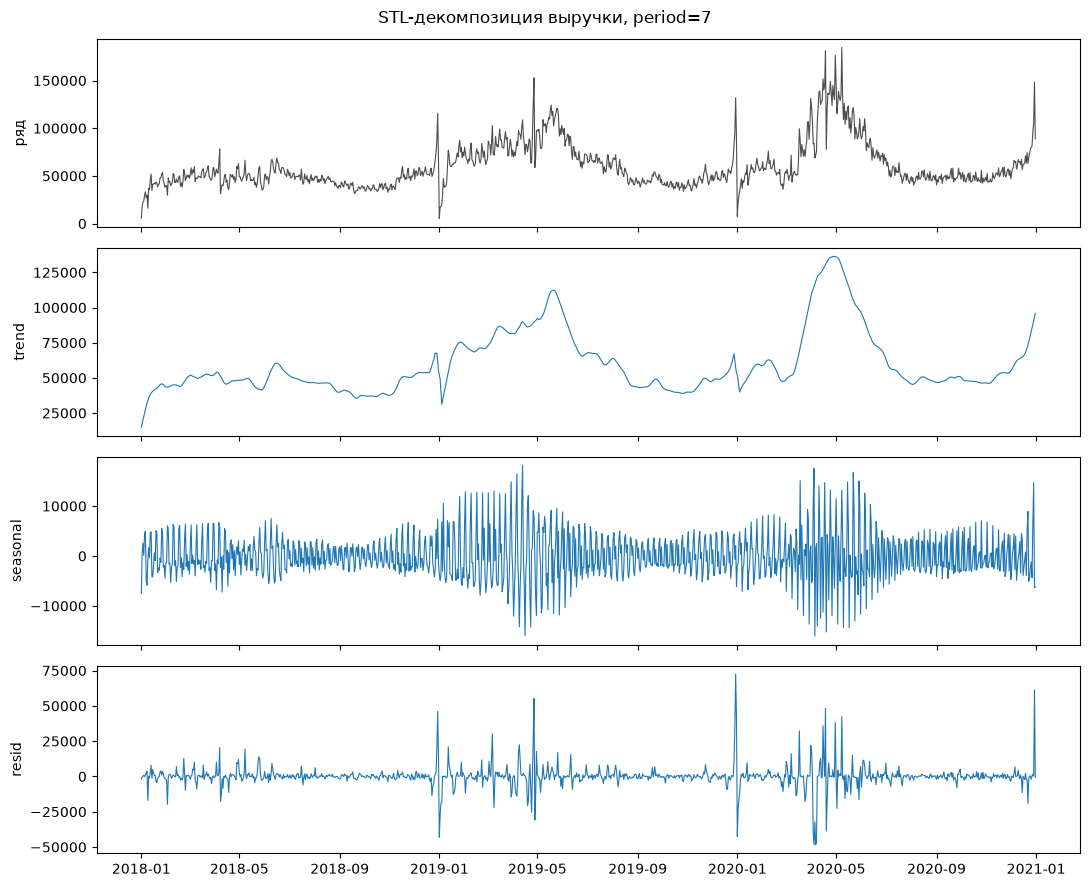

In [5]:
from statsmodels.tsa.seasonal import STL  # noqa: E402

series = raw.set_index("timestamp")["target"].asfreq("D")
stl = STL(series, period=7, robust=True).fit()

components = pd.DataFrame({"trend": stl.trend, "seasonal": stl.seasonal, "resid": stl.resid})
print(components.describe().round(0).to_string())
print("\nсезонная компонента по дням недели:")
print(stl.seasonal.groupby(stl.seasonal.index.dayofweek).mean().round(0).to_string())

fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axes[0].plot(series, lw=0.8, color="0.3")
axes[0].set_ylabel("ряд")
for ax, (name, values) in zip(axes[1:], components.items(), strict=True):
    ax.plot(values, lw=0.8, color="C0")
    ax.set_ylabel(name)
fig.suptitle("STL-декомпозиция выручки, period=7")
plt.tight_layout()
plt.show()

Что видно:

- **тренд** растёт с 15 тыс. в январе 2018 до 96 тыс. в декабре 2020 — это почти всё
  изменение уровня ряда, и по разбросу (22 тыс.) он сравним с самим рядом;
- **сезонность** в типичный день — единицы тысяч (стандартное отклонение 4.6 тыс.):
  пятница и суббота в плюсе (+4.2 и +5.1 тыс.), вторник, среда и воскресенье в минусе
  (−2.6, −2.0 и −2.5 тыс.). Крайние значения (−16 и +18 тыс.) — это уже Новый год,
  а не недельный цикл: STL с `period=7` относит к сезонности всё, что повторяется
  с недельным шагом, включая годовые праздники;
- **остаток** — то, что не объяснено: выбросы, праздники, ковид. Его разброс (7.8 тыс.)
  **больше** разброса сезонности — значит, в ряду есть структура, которой в модели
  «тренд + период 7» нет.

Отдельно стоит заметить масштаб тренда: `LinearTrendTransform` в базе уже даёт модели
тренд. Если подать компоненту `stl_trend` ещё раз, получится **две почти одинаковые
колонки** — классическая мультиколлинеарность.

### Свой трансформ для ETNA

Написать класс на `statsmodels` недостаточно: ETNA должна уметь **продлевать компоненты
за конец истории** — иначе на горизонте прогноза признаков просто не будет.

Правила для своего трансформа:

| Что | Зачем |
|---|---|
| наследоваться от `IrreversibleTransform` | компоненты необратимы, обратного преобразования не нужно |
| `required_features=["target"]` | трансформ читает target, а не экзогенные колонки |
| `_fit` запоминает состояние | уровень тренда, наклон, недельный профиль |
| `_transform` строит колонки на всём диапазоне | включая будущее, для которого `y` неизвестен |
| `get_regressors_info()` перечисляет новые колонки | иначе ETNA не добавит их в признаки |

Продление в будущее — самая ответственная часть. Тренд продолжаем по последнему наклону,
сезонность — повторяя профиль последней недели. Это **допущение**, а не факт: трансформ
не знает, что будет дальше.

In [6]:
class STLDecomposeTransform(IrreversibleTransform):
    """STL-декомпозиция target; компоненты продлеваются за конец истории."""

    def __init__(self, period: int = 7, out_column: str = "stl"):
        super().__init__(required_features=["target"])
        self.period = period
        self.out_column = out_column

    def _fit(self, df: pd.DataFrame):
        self._state = {}
        for segment in df.columns.get_level_values("segment").unique():
            y = df[segment]["target"].dropna()
            fit = STL(y, period=self.period, robust=True).fit()
            self._state[segment] = {
                "last": fit.trend.index[-1],
                "level": float(fit.trend.iloc[-1]),
                "slope": float((fit.trend.iloc[-1] - fit.trend.iloc[-self.period]) / (self.period - 1)),
                "profile": fit.seasonal.iloc[-self.period:].to_numpy(),
                "fitted": pd.DataFrame({"trend": fit.trend, "seasonal": fit.seasonal, "resid": fit.resid}),
            }
        return self

    def _transform(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        for segment in df.columns.get_level_values("segment").unique():
            state = self._state[segment]
            fitted = state["fitted"].reindex(df.index)
            # продолжение тренда и сезонности туда, где истории уже нет
            ahead = pd.Series((df.index - state["last"]).days, index=df.index).clip(lower=0)
            trend = fitted["trend"].fillna(state["level"] + state["slope"] * ahead)
            profile = pd.Series(
                [state["profile"][d % self.period] for d in df.index.dayofweek], index=df.index
            )
            seasonal = fitted["seasonal"].fillna(profile)
            resid = fitted["resid"].fillna(0.0)
            for name, values in (("trend", trend), ("seasonal", seasonal), ("resid", resid)):
                out[(segment, f"{self.out_column}_{name}")] = values
        return out

    def get_regressors_info(self) -> list[str]:
        return [f"{self.out_column}_{name}" for name in ("trend", "seasonal", "resid")]


stl_transform = STLDecomposeTransform()
demo = common.load_onion()
stl_transform.fit_transform(demo)
frame = demo.to_pandas()["onion"]
print(frame[["target", "stl_trend", "stl_seasonal", "stl_resid"]].tail(6).round(0).to_string())

feature       target  stl_trend  stl_seasonal  stl_resid
timestamp                                               
2020-12-26   79702.0    82886.0       -1189.0    -1995.0
2020-12-27   81330.0    85450.0       -4359.0      239.0
2020-12-28   96236.0    88026.0        6616.0     1594.0
2020-12-29  105615.0    90614.0       14721.0      280.0
2020-12-30  148179.0    93211.0       -6353.0    61321.0
2020-12-31   88949.0    95808.0       -6195.0     -665.0


Последние шесть строк — это декабрь 2020, уже конец истории. Здесь `trend` и `seasonal` —
посчитанные STL, а не продление. Чтобы увидеть продление, попросим у ETNA будущее:
`make_future` вернёт даты за концом ряда с пустым `target`, и `_transform` должен
заполнить их сам.

In [7]:
future = demo.make_future(HORIZON)
future.transform([stl_transform])
print(future.to_pandas()["onion"][["target", "stl_trend", "stl_seasonal", "stl_resid"]].round(0).to_string())

feature     target  stl_trend  stl_seasonal  stl_resid
timestamp                                             
2021-01-01     NaN    98389.0       14721.0        0.0
2021-01-02     NaN   100970.0       -6353.0        0.0
2021-01-03     NaN   103552.0       -6195.0        0.0
2021-01-04     NaN   106133.0       -2388.0        0.0
2021-01-05     NaN   108714.0       -1189.0        0.0
2021-01-06     NaN   111295.0       -4359.0        0.0
2021-01-07     NaN   113876.0        6616.0        0.0
2021-01-08     NaN   116457.0       14721.0        0.0
2021-01-09     NaN   119039.0       -6353.0        0.0
2021-01-10     NaN   121620.0       -6195.0        0.0
2021-01-11     NaN   124201.0       -2388.0        0.0
2021-01-12     NaN   126782.0       -1189.0        0.0
2021-01-13     NaN   129363.0       -4359.0        0.0
2021-01-14     NaN   131945.0        6616.0        0.0


Продление работает: `target` пуст, компоненты есть. Заодно видно, **насколько оно
наивное**. Тренд продолжается по наклону последних семи дней — +2581 руб./день, — и к
14 января уходит на 132 тыс. при том, что весь декабрь колебался вокруг 80–100 тыс.
Сезонность просто повторяет недельный профиль последней недели, включая рождественский
всплеск 31 декабря — он попал в профиль и будет повторяться каждую неделю.

Это главный риск своего трансформа: **признак на горизонте — это экстраполяция**, и её
качество определяет, будет ли от такого признака польза. Проверять её надо бэктестом,
а не глазами.

### Что из компонент подавать модели

Теперь замер. Подавать всё сразу — плохая идея по двум причинам: `stl_trend` дублирует
`LinearTrendTransform`, а `stl_seasonal` дублирует дамми дня недели. Остаток же оставим
как есть — интересно, несёт ли он что-то, чего нет в лагах.

In [8]:
results = {
    "база (ноутбук 4)": results["база (ноутбук 4)"],
    "+ все компоненты STL": common.backtest(
        LinearPerSegmentModel(), BASE + [STLDecomposeTransform()], onion, HORIZON
    ),
    "+ только resid": common.backtest(
        LinearPerSegmentModel(),
        BASE + [STLDecomposeTransform(), FilterFeaturesTransform(exclude=["stl_trend", "stl_seasonal"])],
        onion,
        HORIZON,
    ),
    "+ лаги trend и seasonal": common.backtest(
        LinearPerSegmentModel(),
        BASE
        + [
            STLDecomposeTransform(),
            LagTransform(in_column="stl_trend", lags=[14], out_column="lagtrend"),
            LagTransform(in_column="stl_seasonal", lags=[14, 21, 28], out_column="lagseason"),
            FilterFeaturesTransform(exclude=["stl_trend", "stl_seasonal", "stl_resid"]),
        ],
        onion,
        HORIZON,
    ),
}
common.compare(results)

,WAPE,MAE
база (ноутбук 4),0.0947,7053.1767
+ все компоненты STL,0.1603,11342.1838
+ только resid,0.0988,7377.3676
+ лаги trend и seasonal,0.0985,7207.9125


**Все компоненты сразу — катастрофа: 0.1603.** Две причины складываются:

1. `stl_trend` и `LinearTrendTransform` — почти одна и та же колонка. Модель делит
   между ними один эффект, и коэффициенты становятся неустойчивыми.
2. `stl_seasonal` — недельный профиль, который уже выучен дамми дня недели. Ещё одна
   копия того же сигнала.

Убираем дубли — становится почти как база: `resid` 0.0988, лаги компонент 0.0985.

Вывод не в том, что «декомпозиция не работает». Вывод в том, что **декомпозиция — это
способ получить новый взгляд на ряд, а не бесплатные признаки**. Подавать компоненты
имеет смысл, когда модель их ещё не видит: например, в модель без тренда и без дамми
дня недели.

## 4. Готовый `STLTransform` в ETNA и почему он про другое

В ETNA есть `STLTransform`, и легко решить, что это то же самое. Но нет: он
**вычитает** тренд и сезонность из `target` и оставляет модель работать с остатком.
Это не добавление признаков, а **предобработка ряда**.

Проверим, что это даёт: поставим `STLTransform` перед лагами — тогда лаги будут
считаться от очищенного ряда.

In [9]:
results_stl = {
    "база (ноутбук 4)": results["база (ноутбук 4)"],
    "STL вычесть, лаги от остатка": common.backtest(
        LinearPerSegmentModel(),
        CALENDAR
        + [
            HolidayTransform(iso_code="RUS", out_column="holiday"),
            STLTransform(in_column="target", period=7, model="arima", robust=True),
        ]
        + LAGS,
        onion,
        HORIZON,
    ),
}
common.compare(results_stl)

,WAPE,MAE
база (ноутбук 4),0.0947,7053.1767
"STL вычесть, лаги от остатка",0.1238,9139.1170


Стало заметно хуже: 0.1238. Причина в том, что ETNA предупреждает в документации —
`STLTransform` **подвержен look-ahead bias**: для преобразования точки он использует
информацию из всей обучающей части, включая будущее относительно этой точки. Плюс
вычитание тренда лишает модель уровня ряда, а восстанавливать его обратно через
`inverse_transform` по ARIMA-прогнозу тренда — отдельный источник ошибки.

Этот раздел стоит запомнить как пример: **одноимённые вещи в разных библиотеках делают
разное**. `STLTransform` в ETNA — не «признаки из декомпозиции», а «убрать сезонность
перед моделью».

## Итог

| Что добавили | WAPE | Как сделали |
|---|---|---|
| база (ноутбук 4) | 0.0947 | — |
| разность `lag14 - mean28` | 0.0944 | `BinaryOperationTransform` |
| отношение `lag14 / mean28` | **0.0940** | `BinaryOperationTransform` |
| 12 взаимодействий `f365 × dow` | 0.0958 | `BinaryOperationTransform('*')` |
| все компоненты STL | 0.1603 | свой `IrreversibleTransform` |
| только `resid` STL | 0.0988 | свой трансформ + `FilterFeatures` |
| лаги `trend` и `seasonal` | 0.0985 | свой трансформ + `LagTransform` |
| `STLTransform` ETNA, лаги от остатка | 0.1238 | «убрать сезонность» ≠ «добавить признаки» |

Что стоит запомнить:

1. **Арифметика признаков — самый дешёвый способ получить новое.** Отношения и разности
   убирают масштаб и часто полезнее исходных колонок. Одна строка кода, ноль риска.
2. **Взаимодействия стоят коэффициентов.** Произведение двух признаков — это не
   «больше информации», а новый параметр, который надо оценить. Без данных он приносит
   шум.
3. **Декомпозиция — это взгляд, а не признаки.** Тренд и сезонность STL почти всегда
   дублируют то, что модель уже знает из `LinearTrendTransform` и дня недели. Полезен
   не сам тренд, а **остаток** — и то не всегда.
4. **Свой трансформ — это состояние плюс продление.** `_fit` запоминает, `_transform`
   строит колонки на всём диапазоне, включая будущее. Без продления прогноз не
   построится: признаков на горизонте просто не будет.
5. **Читайте, что делает чужая функция.** `STLTransform` в ETNA вычитает компоненты,
   а не извлекает их как признаки, и страдает от look-ahead bias.

Дальше — признаки из нескольких рядов сразу: когда у вас не один магазин, а сотня, часть
сигнала лежит не внутри ряда, а в поперечном разрезе (ноутбук 3 и далее).